# CDS 2413 — Deliverable 1: Data Analysis Report

## COVID-19 Recovery Dataset

###### Purpose: Explore recorded recovery duration and relationships with selected patient characteristics, then perform the sampling, descriptive analysis, visualisation, correlation tests, chi-square test, and one-sample t-test

### 1. Import and inspect

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr, chi2_contingency, shapiro
import scipy

df = pd.read_csv('covid.csv')
print(df.shape)
print(df.head())
print(df.isnull().sum())

(70000, 28)
  patient_id   country region/state  date_reported  age  gender comorbidities  \
0    P000001     India        Sindh          44447   95  Female      Diabetes   
1    P000002  Pakistan       London          43930   92  Female      Diabetes   
2    P000003   Germany       Berlin          44718   78  Female           NaN   
3    P000004     India    Cape Town          44107   36  Female        Cancer   
4    P000005        UK       Berlin          44083   99    Male      Diabetes   

      symptoms_1     symptoms_2     symptoms_3  ... days_to_recovery  \
0          Cough            NaN            NaN  ...               18   
1  Loss of Smell        Fatigue        Fatigue  ...                9   
2       Headache  Loss of Smell  Loss of Smell  ...               27   
3          Cough        Fatigue        Fatigue  ...               25   
4        Fatigue            NaN            NaN  ...               17   

   recovered  death  date_of_recovery date_of_death tests_conducted 

### 2. Data understanding and quality checks

###### Remove only rows where `recovered == 1` and `death == 1`, since these indicators conflict.

In [9]:
df_clean = df[~((df['recovered'] == 1) & (df['death'] == 1))]
print('Original rows:', len(df))
print('Cleaned rows:', len(df_clean))

Original rows: 70000
Cleaned rows: 57514


#### 3. Dependent and independent variables

In [10]:
X = df_clean[['age', 'severity', 'vaccination_status', 'tests_conducted']]
y = df_clean['days_to_recovery']
print(X.head())
print(y.head())

   age  severity vaccination_status  tests_conducted
0   95  Moderate               Full                1
1   92  Moderate                NaN                3
2   78  Critical                NaN                2
4   99      Mild                NaN                4
6   71  Moderate                NaN                3
0    18
1     9
2    27
4    17
6     5
Name: days_to_recovery, dtype: int64


#### 4. Descriptive statistics function

In [11]:
def descriptive_statistics(dataset, field):
    return dataset[field].describe()

print(descriptive_statistics(df_clean, 'days_to_recovery'))

count    57514.000000
mean        17.548301
std          7.517781
min          5.000000
25%         11.000000
50%         18.000000
75%         24.000000
max         30.000000
Name: days_to_recovery, dtype: float64


#### 5. Random sample of 150

In [12]:
random_sample = df_clean.sample(n=150, random_state=42)
print(descriptive_statistics(random_sample, 'days_to_recovery'))

count    150.000000
mean      17.473333
std        7.796658
min        5.000000
25%       10.000000
50%       18.000000
75%       24.750000
max       30.000000
Name: days_to_recovery, dtype: float64


#### 6. Systematic sample of 150

In [13]:
systematic_sample = df_clean.iloc[::383].head(150)
print(descriptive_statistics(systematic_sample, 'days_to_recovery'))

count    150.000000
mean      16.560000
std        7.830829
min        5.000000
25%        9.000000
50%       16.000000
75%       23.750000
max       30.000000
Name: days_to_recovery, dtype: float64


#### 7. Visualizations

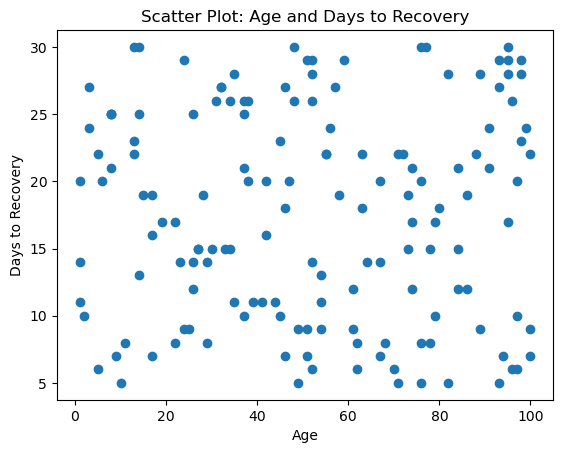

In [14]:
plt.scatter(random_sample['age'], random_sample['days_to_recovery'])
plt.xlabel('Age')
plt.ylabel('Days to Recovery')
plt.title('Scatter Plot: Age and Days to Recovery')
plt.show()

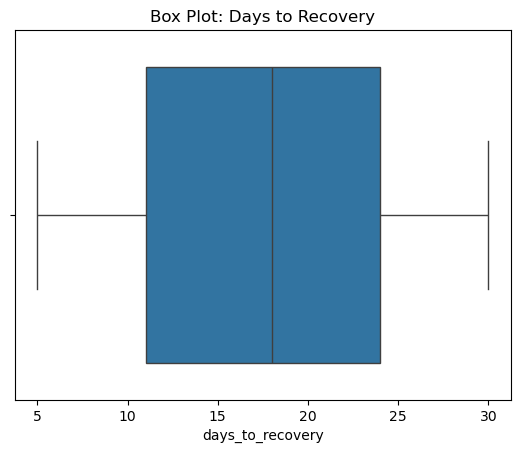

In [15]:
sns.boxplot(x=df_clean['days_to_recovery'])
plt.title('Box Plot: Days to Recovery')
plt.show()

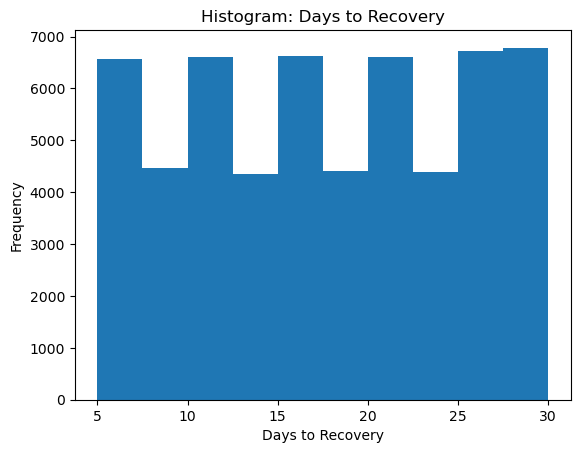

In [16]:
plt.hist(df_clean['days_to_recovery'])
plt.xlabel('Days to Recovery')
plt.ylabel('Frequency')
plt.title('Histogram: Days to Recovery')
plt.show()

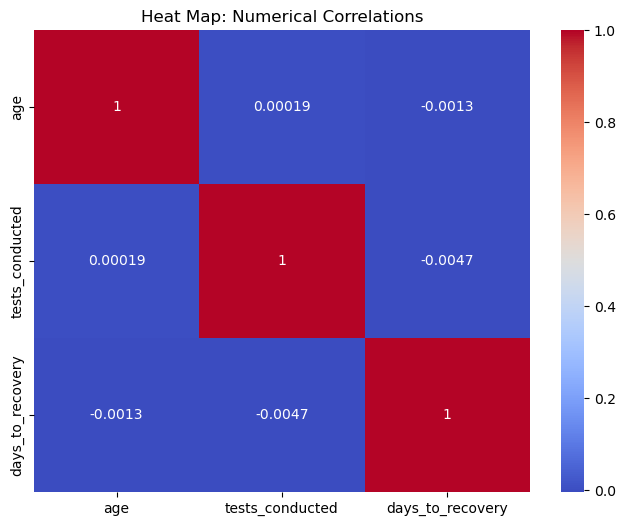

In [18]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    df_clean[['age', 'tests_conducted', 'days_to_recovery']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title('Heat Map: Numerical Correlations')
plt.show()

#### 8. Pearson and Spearman

In [19]:
data = df_clean[['age', 'days_to_recovery']].dropna()
r, p_value = pearsonr(data['age'], data['days_to_recovery'])
print(f'Pearson r: {r:.4f}, p-value: {p_value:.4f}')
if p_value < 0.05:
    print('Reject H0')
else:
    print('Fail to reject H0')

r, p_value = spearmanr(data['age'], data['days_to_recovery'])
print(f'Spearman r: {r:.4f}, p-value: {p_value:.4f}')
if p_value < 0.05:
    print('Reject H0')
else:
    print('Fail to reject H0')

Pearson r: -0.0013, p-value: 0.7485
Fail to reject H0
Spearman r: -0.0013, p-value: 0.7557
Fail to reject H0


#### 9. Chi-square (categorical outcome)

In [20]:
contingency_data = pd.crosstab(df_clean['severity'], df_clean['recovered'], margins=False)
print(contingency_data)
r, p, dof, expected = chi2_contingency(contingency_data)
print('Chi-square = %.3f, p = %.3f' % (r, p))
print('Degrees of freedom:', dof)
if p > 0.05:
    print('independent categories (fail to reject H0)')
else:
    print('dependent categories (reject H0)')

recovered      0     1
severity              
Critical    2750   479
Mild       31989  2044
Moderate   13407   859
Severe      5309   677
Chi-square = 543.457, p = 0.000
Degrees of freedom: 3
dependent categories (reject H0)


#### 10. Normality and one-sample t-test

In [21]:
r, p = shapiro(random_sample['days_to_recovery'])
print('Shapiro W=%.3f, p=%.6f' % (r, p))
if p > 0.05:
    print('Normal distribution: fail to reject H0')
else:
    print('Not a normal distribution: reject H0')

population_mean = df_clean['days_to_recovery'].mean()
print('Reference mean:', population_mean)
print(scipy.stats.ttest_1samp(random_sample['days_to_recovery'], population_mean))

Shapiro W=0.939, p=0.000004
Not a normal distribution: reject H0
Reference mean: 17.548301283165838
TtestResult(statistic=np.float64(-0.11776406380666768), pvalue=np.float64(0.9064132051991718), df=np.int64(149))
